# Yield Curve Regimes & Equity Positioning
## Week 4: Check the labels, then pair them with next month’s returns

**Research question:** How have U.S. stock sectors performed in each yield-curve environment since 1976, and what does today’s environment suggest about which sectors are best positioned?

This week has two parts:
1. **Check the labels** during three periods you know well: the 2008 financial crisis, the 2022 rate hikes, and the recent inversion and rate cuts.
2. **Pair each month’s label with the following month’s returns**, so every result uses only what an investor knew at the time.

**How to run it:** upload it to [Google Colab](https://colab.research.google.com) (File → Upload notebook), then **Runtime → Run all**. It loads `monthly_with_regimes.csv` from your GitHub repository.

### 1. Load your labeled dataset
**What this does:** reads the Week 3 output, your data plus the `regime` column. If a copy is already in Colab’s folder it uses that, and if GitHub can’t be reached it shows an upload button.

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

GITHUB_CSV = "https://raw.githubusercontent.com/caden-smalls-greenwood/yield-curve-regimes/main/monthly_with_regimes.csv"
LOCAL_CSV  = Path("monthly_with_regimes.csv")
DATA = Path("data");    DATA.mkdir(exist_ok=True)
FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)

def load_dataset():
    if LOCAL_CSV.exists():
        print("Using the monthly_with_regimes.csv already in this folder.")
        return pd.read_csv(LOCAL_CSV)
    try:
        r = requests.get(GITHUB_CSV, timeout=30)
        r.raise_for_status()
        print("Loaded monthly_with_regimes.csv from your GitHub repository.")
        return pd.read_csv(io.StringIO(r.text))
    except requests.RequestException as e:
        print(f"Couldn't reach GitHub ({type(e).__name__}). Click 'Choose Files' and pick monthly_with_regimes.csv.")
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError("Put monthly_with_regimes.csv in this notebook's folder and run this cell again.")
        uploaded = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))

raw = load_dataset()
data = raw.set_index(pd.PeriodIndex(raw["month"], freq="M")).drop(columns="month")

SECTORS = ["Nondurables", "Durables", "Manufacturing", "Energy", "Chemicals", "Tech",
           "Telecom", "Utilities", "Retail", "Healthcare", "Finance", "Other"]
REGIMES = ["Bull steepener", "Bear steepener", "Bull flattener", "Bear flattener"]
print(f"{len(data)} months, {data.index.min()} to {data.index.max()}; "
      f"{data['regime'].notna().sum()} have a regime label")

Using the monthly_with_regimes.csv already in this folder.
604 months, 1976-06 to 2026-09; 601 have a regime label


### 2. Check the labels during three periods you know
If the labels make sense, each period should look the way its history suggests:

| Period | What happened | Label you’d expect most |
|---|---|---|
| Jul 2007 – Jun 2009 | Financial crisis; the Fed cut rates from 5.25% to near zero | **Bull steepener** |
| Jan 2022 – Dec 2023 | The Fed raised rates from near zero to over 5% to fight inflation | **Bear flattener** |
| Jan 2024 – latest | The curve un-inverted and the Fed started cutting in September 2024 | Mixed, with a **bull steepener** around September 2024 |

In [2]:
EPISODES = {
    "Financial crisis (Jul 2007 – Jun 2009)": ("2007-07", "2009-06"),
    "Fed hiking cycle (Jan 2022 – Dec 2023)": ("2022-01", "2023-12"),
    "Un-inversion and cuts (Jan 2024 – latest)": ("2024-01", str(data.index.max())),
}
for name, (start, end) in EPISODES.items():
    counts = data.loc[start:end, "regime"].value_counts().reindex(REGIMES).fillna(0).astype(int)
    total = counts.sum()
    print(name)
    for regime, n in counts.items():
        print(f"   {regime:15s} {n:>3} of {total} months  {'█' * n}")
    print()

Financial crisis (Jul 2007 – Jun 2009)
   Bull steepener   11 of 24 months  ███████████
   Bear steepener    7 of 24 months  ███████
   Bull flattener    2 of 24 months  ██
   Bear flattener    4 of 24 months  ████

Fed hiking cycle (Jan 2022 – Dec 2023)
   Bull steepener    3 of 24 months  ███
   Bear steepener    4 of 24 months  ████
   Bull flattener    3 of 24 months  ███
   Bear flattener   14 of 24 months  ██████████████

Un-inversion and cuts (Jan 2024 – latest)
   Bull steepener    9 of 33 months  █████████
   Bear steepener   12 of 33 months  ████████████
   Bull flattener    3 of 33 months  ███
   Bear flattener    9 of 33 months  █████████



Now look month by month around the moment the Fed started cutting in 2024. The 10y–2y spread turned positive again in August–September 2024, ending the long inversion.

In [3]:
data.loc["2024-05":"2024-12", ["y10", "y2", "spread_10y2y", "fed_funds", "chg_10y", "chg_slope", "regime"]]

,y10,y2,spread_10y2y,fed_funds,chg_10y,chg_slope,regime
month,,,,,,,
2024-05,4.51,4.89,-0.38,5.33,0.26,0.01,Bear steepener
2024-06,4.36,4.71,-0.35,5.33,0.16,0.04,Bear steepener
2024-07,4.09,4.29,-0.20,5.33,-0.60,0.15,Bull steepener
2024-08,3.91,3.91,0.00,5.33,-0.60,0.38,Bull steepener
2024-09,3.81,3.66,0.15,5.13,-0.55,0.50,Bull steepener
2024-10,4.28,4.16,0.12,4.83,0.19,0.32,Bear steepener
2024-11,4.18,4.13,0.05,4.64,0.27,0.05,Bear steepener
2024-12,4.58,4.25,0.33,4.48,0.77,0.18,Bear steepener


### 3. Pair each month’s returns with the label known at the start of that month
This is the key step of the whole project, so here it is slowly.

- The label for **March 2008** is known on **March 31, 2008**.
- The first month you could invest using it is **April 2008**.
- So April’s returns must be compared with **March’s** label.

**How the code does it:** it makes a new column, `regime_known`, by moving every label **down one row**, which is `shift(1)`. After that, each month’s row shows its own returns next to the label from the month before, the one an investor actually knew at the start of the month.

This is the safe direction: `shift(1)` looks **back**, just like the Week 3 labels did. Nothing from the future touches the label.

In [4]:
data["regime_known"] = data["regime"].shift(1)

data.loc["2008-02":"2008-05", ["regime", "regime_known", "Market", "Finance"]]

,regime,regime_known,Market,Finance
month,,,,
2008-02,Bull steepener,Bull steepener,-0.0296,-0.1081
2008-03,Bull steepener,Bull steepener,-0.0077,-0.0393
2008-04,Bear flattener,Bull steepener,0.0479,0.0551
2008-05,Bear flattener,Bear flattener,0.0205,-0.0423


Read the table above row by row: **April 2008**’s `regime_known` is **March 2008**’s `regime`. That’s the pairing working.

### 4. Spot-check a few months
Each row is one month’s returns next to the label known when that month began. Returns are shown in percent.

In [5]:
spot = ["2008-04", "2008-10", "2022-10", "2023-11"]
check = data.loc[[pd.Period(m, "M") for m in spot], ["regime_known", "Market", "Finance", "Tech", "Utilities"]].copy()
for col in ["Market", "Finance", "Tech", "Utilities"]:
    check[col] = (check[col] * 100).round(1)
check

,regime_known,Market,Finance,Tech,Utilities
month,,,,,
2008-04,Bull steepener,4.8,5.5,6.5,6.4
2008-10,Bull steepener,-17.1,-20.2,-18.1,-11.1
2022-10,Bear flattener,8.1,12.7,5.0,3.4
2023-11,Bear steepener,9.3,10.2,12.0,5.1


**Look at October 2008:** the label known at the end of September was a bull steepener, and the market then fell **17.1%** in a single month, the week-by-week collapse after Lehman Brothers. One month can swing wildly whatever the label says. That’s why the project averages over **all** months in each regime instead of trusting any single one.

### 5. Build the paired dataset
Only months that have **both** a known label and published returns count:
- The first is October 1976, using September 1976’s label.
- The last is the newest month Ken French has published.

In [6]:
RETURNS = ["Market", "RF"] + SECTORS
paired = data.loc[data["regime_known"].notna() & data["Market"].notna(), ["regime_known"] + RETURNS]

print(f"Paired months: {len(paired)}, {paired.index.min()} to {paired.index.max()}\n")
counts = paired["regime_known"].value_counts().reindex(REGIMES)
for regime, n in counts.items():
    print(f"  {regime:15s} {n:>4} months")

Paired months: 599, 1976-10 to 2026-08

  Bull steepener   133 months
  Bear steepener   136 months
  Bull flattener   156 months
  Bear flattener   174 months


### 6. A first peek: the average next-month market return in each regime
This is just the **whole market**, and just the **average**. Week 5 does all 12 sectors properly and compares each against the market.

**Read this with care:** the market moves about ±4–5% in a typical month. With roughly 130–175 months per regime, an average can easily be off by a few tenths of a percent through luck alone. The **"± range"** column shows that uncertainty (one standard error). If two regimes’ ranges overlap a lot, the difference between them may just be noise.

In [7]:
stats = paired.groupby("regime_known")["Market"].agg(["mean", "std", "count"]).reindex(REGIMES)
stats["± range"] = stats["std"] / np.sqrt(stats["count"])          # standard error of the average
peek = pd.DataFrame({
    "Avg next-month return (%)": (stats["mean"] * 100).round(2),
    "± range (%)": (stats["± range"] * 100).round(2),
    "Months": stats["count"].astype(int),
})
print(peek.to_string())
print(f"\nAll months together: {paired['Market'].mean() * 100:.2f}% per month")

                Avg next-month return (%)  ± range (%)  Months
regime_known                                                  
Bull steepener                       1.32         0.45     133
Bear steepener                       0.97         0.38     136
Bull flattener                       1.21         0.33     156
Bear flattener                       0.79         0.32     174

All months together: 1.06% per month


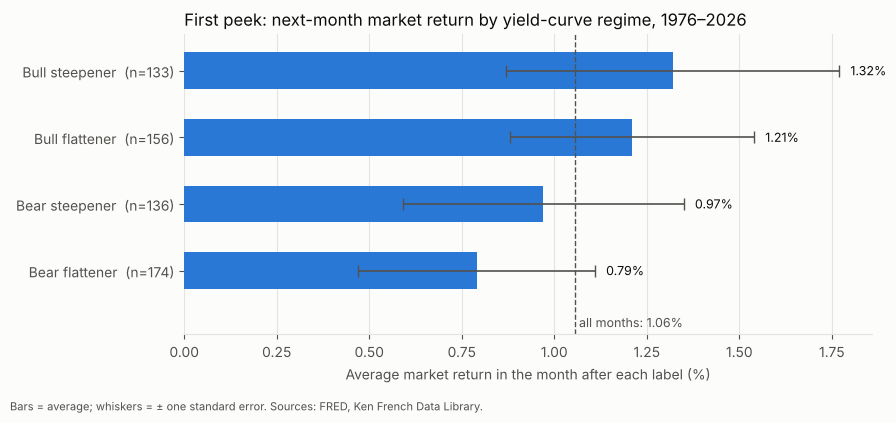

In [8]:
INK, MUTED, GRID, BG, BLUE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#2a78d6"
order = peek.sort_values("Avg next-month return (%)").index
vals, errs = peek.loc[order, "Avg next-month return (%)"], peek.loc[order, "± range (%)"]

fig, ax = plt.subplots(figsize=(9, 4.2), facecolor=BG)
ax.set_facecolor(BG)
ax.barh(range(len(order)), vals, height=0.55, color=BLUE, xerr=errs,
        error_kw={"ecolor": MUTED, "elinewidth": 1.2, "capsize": 4})
ax.axvline(paired["Market"].mean() * 100, color=MUTED, linewidth=1, linestyle="--")
ax.set_ylim(-0.95, len(order) - 0.45)
ax.text(paired["Market"].mean() * 100, -0.78, f" all months: {paired['Market'].mean() * 100:.2f}%", color=MUTED, fontsize=9, va="center")
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{r}  (n={peek.loc[r, 'Months']})" for r in order], color=INK)
for i, v in enumerate(vals):
    ax.text(v + errs.iloc[i] + 0.03, i, f"{v:.2f}%", va="center", color=INK, fontsize=9)
ax.set_xlabel("Average market return in the month after each label (%)", color=MUTED)
ax.set_title("First peek: next-month market return by yield-curve regime, 1976–2026", loc="left", color=INK, fontsize=12)
ax.tick_params(colors=MUTED)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
fig.text(0.01, 0.01, "Bars = average; whiskers = ± one standard error. Sources: FRED, Ken French Data Library.",
         color=MUTED, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIGS / "first_peek_market_by_regime.png", dpi=200, facecolor=BG)
plt.show()

### 7. Save the paired dataset for Week 5
This writes `data/regime_next_month_returns.csv`: one row per month, with that month’s returns and the label known at the start of it. Week 5 runs all its sector comparisons from this file. Upload it, the chart and this notebook to your GitHub repository.

In [9]:
paired.round(4).to_csv(DATA / "regime_next_month_returns.csv")
print("Saved", DATA / "regime_next_month_returns.csv", "-", len(paired), "rows")

try:                                   # only works inside Google Colab
    from google.colab import files
    files.download(str(DATA / "regime_next_month_returns.csv"))
    files.download(str(FIGS / "first_peek_market_by_regime.png"))
except ImportError:
    print("Not running in Colab: find the files in the data/ and figures/ folders.")

Saved data/regime_next_month_returns.csv - 599 rows
Not running in Colab: find the files in the data/ and figures/ folders.


### 8. Week 4 study questions
1. The notebook moves each label **down one row** (`shift(1)`). Explain in your own words why that pairs March’s label with April’s returns, and why it doesn’t create look-ahead bias.
2. October 2008 followed a bull steepener label and the market fell 17.1%. What does that tell you about judging a regime by any single month?
3. In the first peek, which regime had the highest average next-month market return, and which the lowest? How does that compare with your Week 2 guesses?
4. Why might a gap of about half a percent per month between two regimes still be noise? Use the “± range” column in your answer.
5. During the 2022–2023 hiking cycle, which label showed up most? What label appeared when the Fed started cutting in September 2024?

**Next (Week 5):** the same comparison for all 12 sectors, measured against the market, plus how often each sector beats the market, shown as a heatmap.